In [1]:
import os

import torch
from sklearn.preprocessing import StandardScaler

from msi_vae.analysis import *
from msi_vae.data import *
from msi_vae.models import *
from msi_vae.msi_dataset import *

In [2]:
DEVICE = get_torch_device()

In [3]:
assets_path = os.path.join(os.path.dirname(os.getcwd()), "assets")
latest_run_id = get_latest_run_id(os.path.join(assets_path, "weights"))
print(f"The latest run ID is: {latest_run_id}")

The latest run ID is: vae_msi_20251218-181743


In [4]:
hparams = load_hyperparameters(assets_path, latest_run_id)

In [5]:
model = VAE(
    hparams["input_dim"],
    hparams["latent_dim"],
    hparams["beta"],
    [hparams["dimensions_1"], hparams["dimensions_2"]],
    hparams["loss_type"],
).to(DEVICE)

In [6]:
model.load_state_dict(
    torch.load(os.path.join(assets_path, "weights", f"{latest_run_id}.pth"))
)
model.eval()

VAE(
  (linear_1_enc): Linear(in_features=70000, out_features=2048, bias=True)
  (linear_1_enc_batch_norm): BatchNorm1d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (linear_2_enc): Linear(in_features=2048, out_features=512, bias=True)
  (linear_2_enc_batch_norm): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (mean): Linear(in_features=512, out_features=200, bias=True)
  (mean_batch_norm): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (log_var): Linear(in_features=512, out_features=200, bias=True)
  (log_var_batch_norm): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (linear_1_dec): Linear(in_features=200, out_features=512, bias=True)
  (linear_1_dec_batch_norm): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (linear_2_dec): Linear(in_features=512, out_features=2048, bias=True)
  (linear_2_dec_batch_norm): BatchNorm1

In [7]:
test_data = MSIDataset(
    hparams["path"],
    "test",
    hparams["input_dim"],
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=hparams["batch_size"],
    shuffle=False,
    num_workers=0,
)

In [8]:
analysis_path = os.path.join(assets_path, "analysis", latest_run_id)
os.makedirs(analysis_path, exist_ok=True)

In [9]:
tsne_file = "tsne.npy"
tsne_scaled_file = "tnse_scaled.npy"
umap_file = "umap.npy"
umap_scaled_file = "umap_scaled.npy"
means_file = "means.npy"

In [10]:
means = run_encoding(
    os.path.join(analysis_path, means_file), model, test_loader, DEVICE
)
print(f"Means shape: {means.shape}")

Encoding:   0%|          | 0/2500 [00:00<?, ?it/s]

Means shape: (160000, 200)


In [11]:
z = StandardScaler().fit_transform(means)

In [12]:
tsne_results = run_tsne(os.path.join(analysis_path, tsne_file), means)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 160000 samples in 0.006s...
[t-SNE] Computed neighbors for 160000 samples in 22.862s...
[t-SNE] Computed conditional probabilities for sample 1000 / 160000
[t-SNE] Computed conditional probabilities for sample 2000 / 160000
[t-SNE] Computed conditional probabilities for sample 3000 / 160000
[t-SNE] Computed conditional probabilities for sample 4000 / 160000
[t-SNE] Computed conditional probabilities for sample 5000 / 160000
[t-SNE] Computed conditional probabilities for sample 6000 / 160000
[t-SNE] Computed conditional probabilities for sample 7000 / 160000
[t-SNE] Computed conditional probabilities for sample 8000 / 160000
[t-SNE] Computed conditional probabilities for sample 9000 / 160000
[t-SNE] Computed conditional probabilities for sample 10000 / 160000
[t-SNE] Computed conditional probabilities for sample 11000 / 160000
[t-SNE] Computed conditional probabilities for sample 12000 / 160000
[t-SNE] Computed conditional probab

In [13]:
tsne_scaled_results = run_tsne(os.path.join(analysis_path, tsne_scaled_file), z)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 160000 samples in 0.007s...
[t-SNE] Computed neighbors for 160000 samples in 21.094s...
[t-SNE] Computed conditional probabilities for sample 1000 / 160000
[t-SNE] Computed conditional probabilities for sample 2000 / 160000
[t-SNE] Computed conditional probabilities for sample 3000 / 160000
[t-SNE] Computed conditional probabilities for sample 4000 / 160000
[t-SNE] Computed conditional probabilities for sample 5000 / 160000
[t-SNE] Computed conditional probabilities for sample 6000 / 160000
[t-SNE] Computed conditional probabilities for sample 7000 / 160000
[t-SNE] Computed conditional probabilities for sample 8000 / 160000
[t-SNE] Computed conditional probabilities for sample 9000 / 160000
[t-SNE] Computed conditional probabilities for sample 10000 / 160000
[t-SNE] Computed conditional probabilities for sample 11000 / 160000
[t-SNE] Computed conditional probabilities for sample 12000 / 160000
[t-SNE] Computed conditional probab

In [14]:
tsne_plot_title = "VAE Latent Space with t-SNE"
standardised_tsne_plot_title = "VAE Standardised Latent Space with t-SNE"

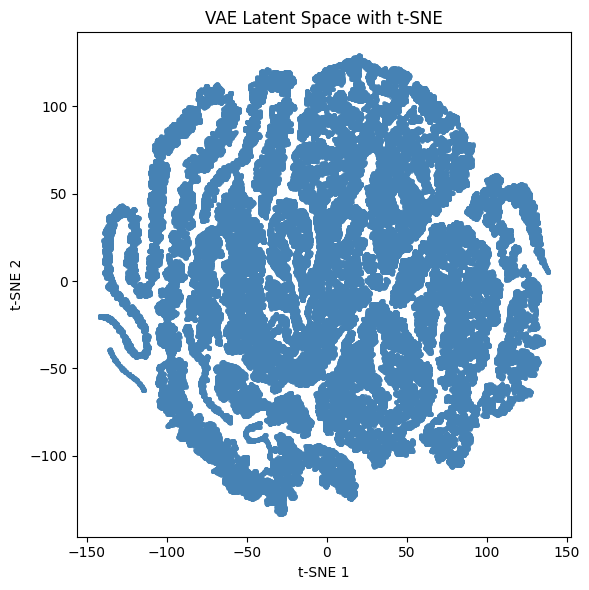

In [15]:
visualize_latent_space_with_tsne(tsne_results, tsne_plot_title)

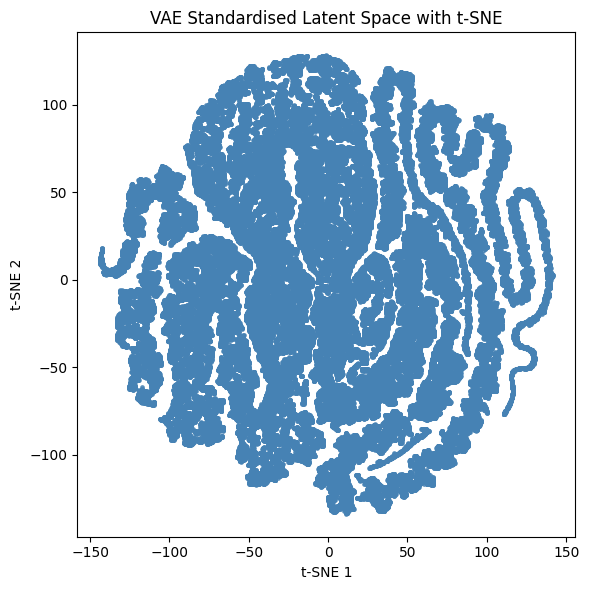

In [16]:
visualize_latent_space_with_tsne(tsne_scaled_results, standardised_tsne_plot_title)

k=2, inertia=1.41
k=3, inertia=0.73
k=4, inertia=0.43
k=5, inertia=0.29
k=6, inertia=0.21
k=7, inertia=0.16
k=8, inertia=0.12
k=9, inertia=0.10
k=10, inertia=0.08
k=11, inertia=0.07
k=12, inertia=0.06
k=13, inertia=0.05
k=14, inertia=0.04
k=15, inertia=0.04
k=16, inertia=0.03
k=17, inertia=0.03
k=18, inertia=0.03
k=19, inertia=0.03
k=20, inertia=0.02
k=21, inertia=0.02
k=22, inertia=0.02
k=23, inertia=0.02
k=24, inertia=0.02
k=25, inertia=0.02
k=26, inertia=0.02
k=27, inertia=0.01
k=28, inertia=0.01
k=29, inertia=0.01
k=30, inertia=0.01


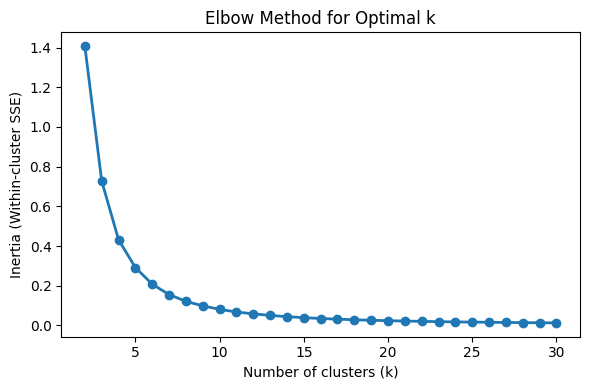

In [17]:
inertias = find_optimal_k(
    means, k_min=2, k_max=30, save_path=os.path.join(analysis_path, "elbow.svg")
)

In [18]:
best_k = int(input("Optimal number of clusters using elbow method"))
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init="auto")
cluster_labels = kmeans.fit_predict(means)

print("Cluster counts:", np.bincount(cluster_labels))

Cluster counts: [25084  6346 29231  3425 14122 24741  1833  4999 19022 13991  7776  9430]


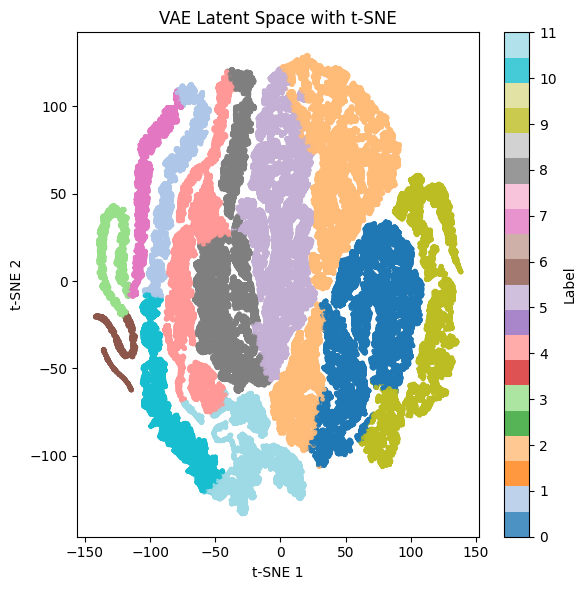

In [19]:
visualize_latent_space_with_tsne(
    tsne_results,
    tsne_plot_title,
    cluster_labels,
    os.path.join(analysis_path, "tsne.svg"),
)

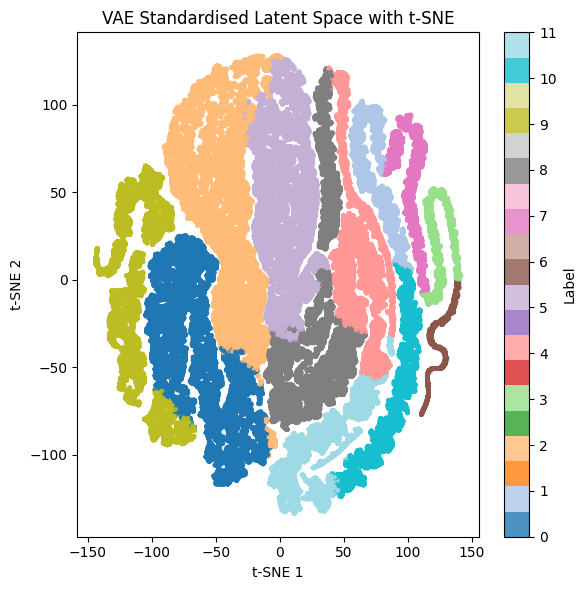

In [20]:
visualize_latent_space_with_tsne(
    tsne_scaled_results,
    standardised_tsne_plot_title,
    cluster_labels,
    os.path.join(analysis_path, "tsne_standardised.svg"),
)

In [21]:
cluster_centroid_spectra = convert_cluster_centers_to_spectra(
    model, kmeans, DEVICE, os.path.join(analysis_path, "cluster_centroid_spectra.npy")
)

print(f"Cluster centroid spectra shape: {cluster_centroid_spectra.shape}")

Cluster centroid spectra shape: (12, 70000)


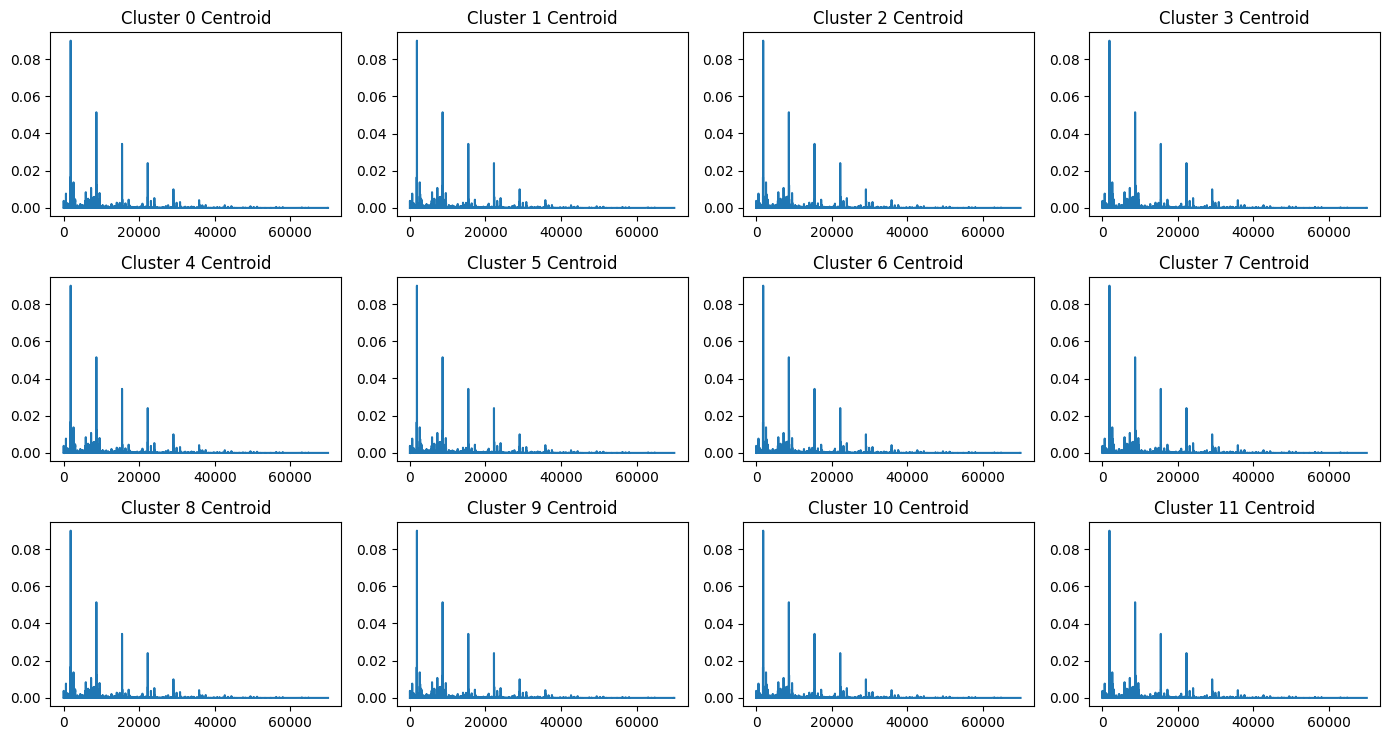

In [22]:
plot_cluster_centroid_spectra(
    cluster_centroid_spectra,
    os.path.join(analysis_path, "cluster_centroid_spectra.svg"),
)

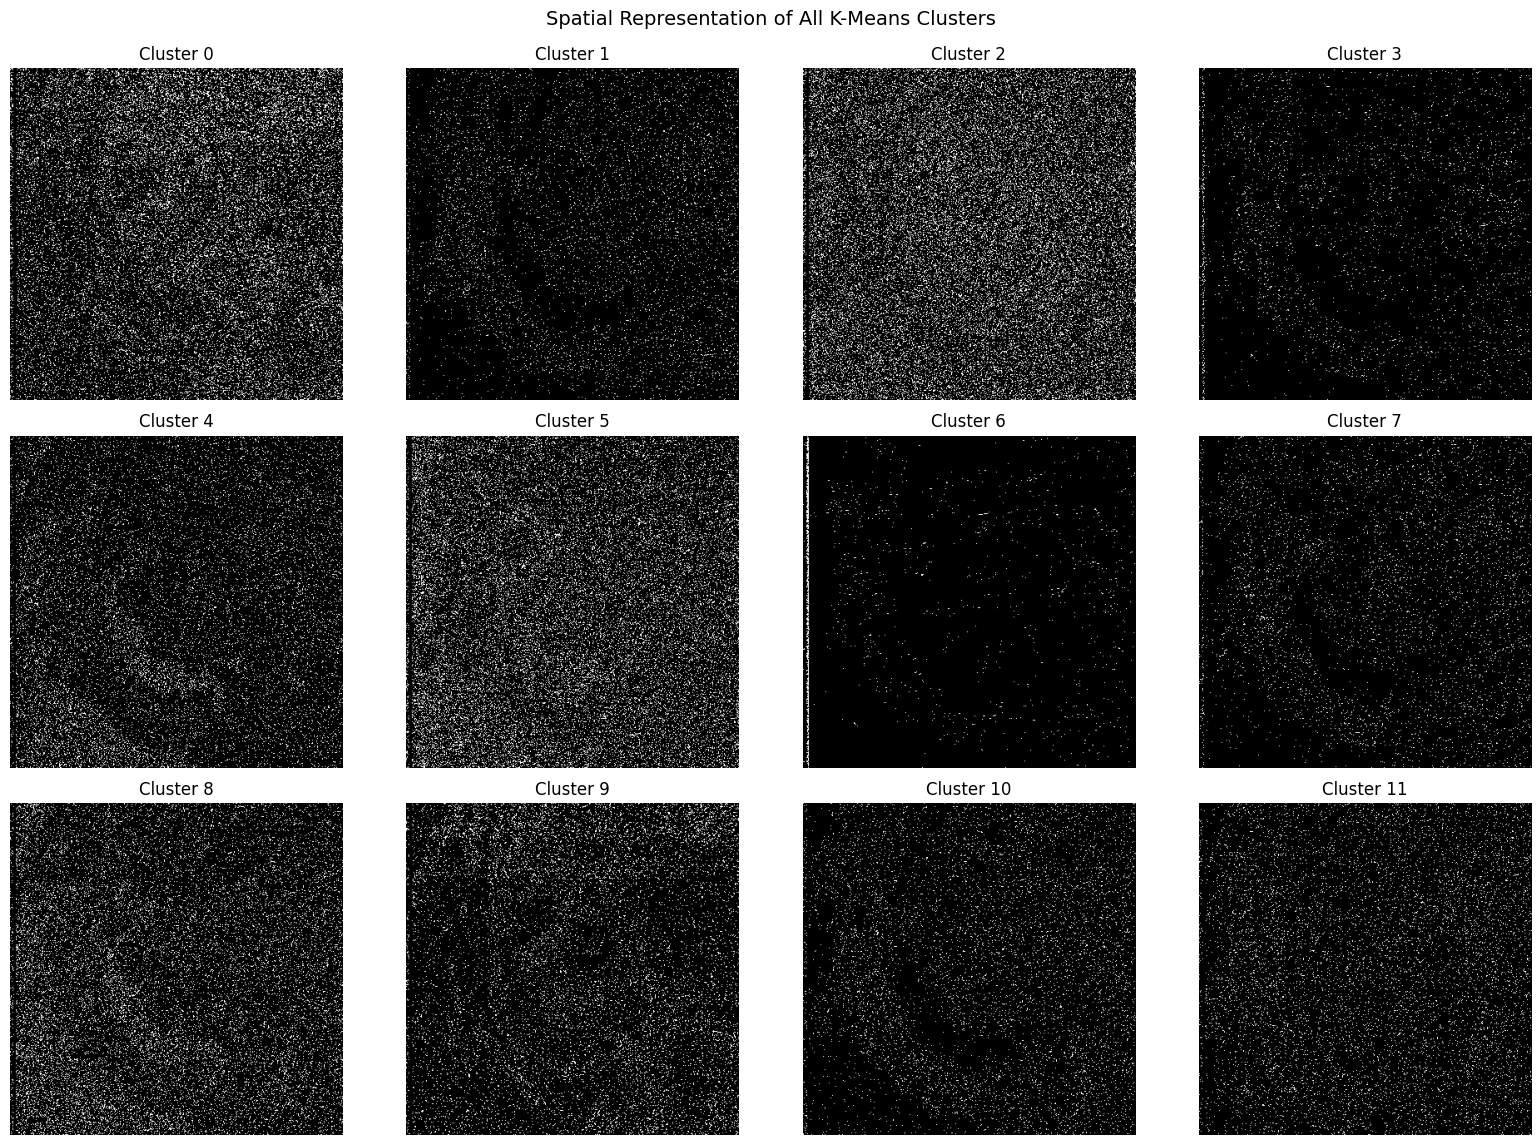

In [23]:
plot_all_clusters(
    cluster_labels, (400, 400), best_k, os.path.join(analysis_path, "all_spatial.svg")
)

In [24]:
def compute_summary_spectra(dataset):
    first = dataset[0]
    n_bins = first.numel()

    sum_spectrum = torch.zeros(n_bins)
    max_spectrum = torch.full((n_bins,), float("-inf"))
    min_spectrum = torch.full((n_bins,), float("inf"))

    for spectrum in dataset:
        spectrum = spectrum.detach().cpu().float()
        sum_spectrum += spectrum
        max_spectrum = torch.max(max_spectrum, spectrum)
        min_spectrum = torch.min(min_spectrum, spectrum)

    mean_spectrum = sum_spectrum / len(dataset)
    return mean_spectrum, max_spectrum, min_spectrum


mean_spectrum, max_spectrum, min_spectrum = compute_summary_spectra(test_data)

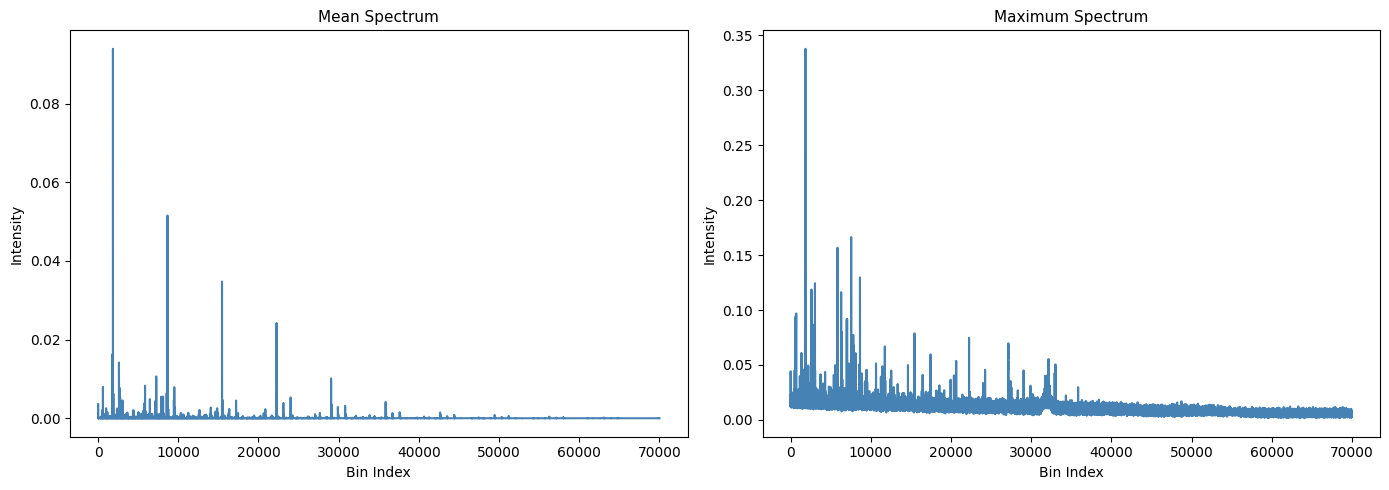

In [25]:
plot_summary_spectra(
    mean_spectrum,
    max_spectrum,
    save_path=os.path.join(analysis_path, "summary_spectra.svg"),
)